# SC08 — Step 2: Data Preparation & Exploratory Data Analysis
**Machine Predictive Maintenance & Fault Priority System**

This notebook provides a fully executed, reproducible demonstration of dataset loading, exploratory analysis, preprocessing, feature encoding, stratified train/test splitting, and normalization for the UCI AI4I 2020 Predictive Maintenance Dataset.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.prepare_data import prepare_data

raw_path = os.path.join("data", "raw", "ai4i2020.csv")
print("Packages loaded successfully.")
print(f"Data path: {raw_path}")

Packages loaded successfully.
Data path: data\raw\ai4i2020.csv


In [2]:
df = pd.read_csv(raw_path)
print(f"Dataset Shape: {df.shape} ({df.shape[0]:,} rows, {df.shape[1]} columns)")
print("\nColumns:")
for i, col in enumerate(df.columns):
    print(f"  {i+1}. {col}")

Dataset Shape: (10000, 12) (10,000 rows, 12 columns)

Columns:
  1. Type
  2. Air temperature [K]
  3. Process temperature [K]
  4. Rotational speed [rpm]
  5. Torque [Nm]
  6. Tool wear [min]
  7. Machine failure
  8. TWF
  9. HDF
  10. PWF
  11. OSF
  12. RNF


In [3]:
print("Missing Values per Column:")
print(df.isnull().sum())
print(f"\nTotal Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

Missing Values per Column:
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0

Total Missing Values: 0
Duplicate Rows: 0


In [4]:
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
print("Continuous Feature Statistics:")
print(df[num_cols].describe().T[["min", "max", "mean", "std"]])

Continuous Feature Statistics:
                            min     max        mean         std
Air temperature [K]       295.3   304.5   300.00493    2.000259
Process temperature [K]   305.7   313.8   310.00556    1.483734
Rotational speed [rpm]   1168.0  2886.0  1538.77610  179.284096
Torque [Nm]                 3.8    76.6    39.98691    9.968934
Tool wear [min]             0.0   253.0   107.95100   63.654147


In [5]:
target_counts = df["Machine failure"].value_counts()
target_pcts = df["Machine failure"].value_counts(normalize=True) * 100
print("Target Class Distribution ('Machine failure'):")
print(f"0 (Healthy)    : {target_counts[0]:5d} ({target_pcts[0]:.2f}%)")
print(f"1 (Failure)    : {target_counts[1]:5d} ({target_pcts[1]:.2f}%)")
print("\nSub-failure Mode Occurrences:")
for sub in ["TWF", "HDF", "PWF", "OSF", "RNF"]:
    print(f"{sub:28s}: {df[sub].sum()}")

Target Class Distribution ('Machine failure'):
0 (Healthy)    :  9661 (96.61%)
1 (Failure)    :   339 (3.39%)

Sub-failure Mode Occurrences:
TWF (Tool Wear Failure)      : 46
HDF (Heat Dissipation Failure): 115
PWF (Power Failure)           : 95
OSF (Overstrain Failure)      : 98
RNF (Random Failure)          : 19


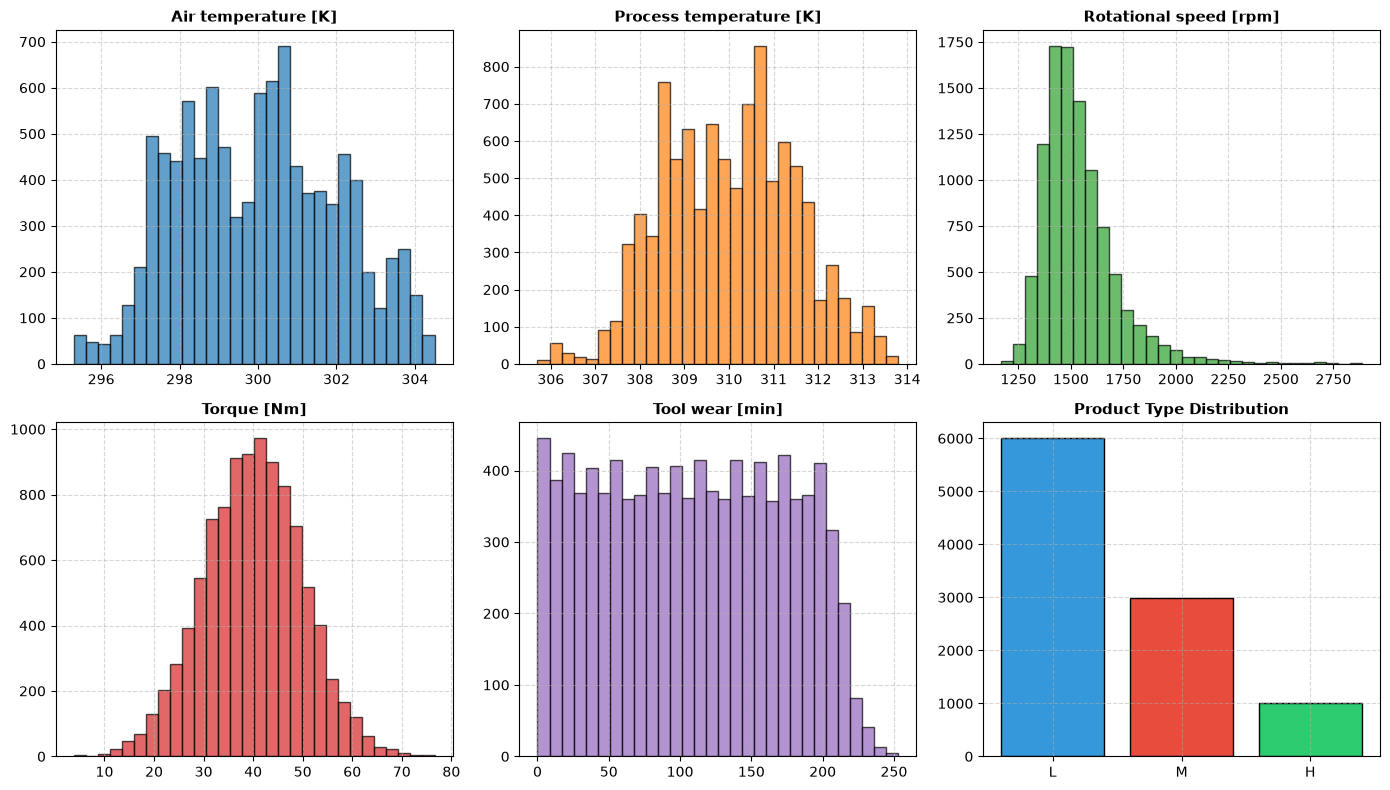

In [6]:
# Visualize feature distributions
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"]
for i, col in enumerate(num_cols):
    axes[i].hist(df[col], bins=30, color=colors[i], alpha=0.7, edgecolor="black")
    axes[i].set_title(col, fontsize=11, fontweight="bold")
    axes[i].grid(True, linestyle="--", alpha=0.5)

type_counts = df["Type"].value_counts()
axes[5].bar(type_counts.index, type_counts.values, color=["#3498db", "#e74c3c", "#2ecc71"], edgecolor="black")
axes[5].set_title("Product Type Distribution", fontsize=11, fontweight="bold")
axes[5].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

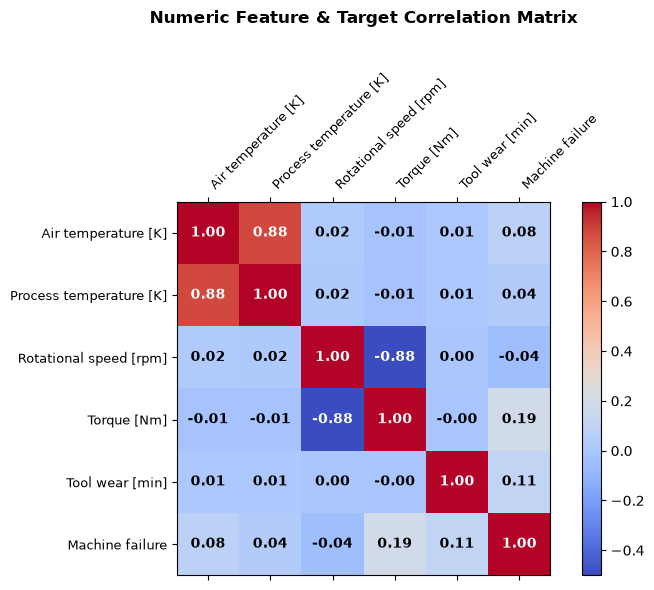

In [7]:
# Correlation Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[num_cols + ["Machine failure"]].corr()
cax = ax.matshow(corr, cmap="coolwarm", vmin=-0.5, vmax=1)
fig.colorbar(cax)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="left", fontsize=9)
ax.set_yticklabels(corr.columns, fontsize=9)
for (i, j), z in np.ndenumerate(corr):
    ax.text(j, i, f"{z:.2f}", ha="center", va="center", color="black" if abs(z)<0.4 else "white", fontweight="bold")
plt.title("Numeric Feature & Target Correlation Matrix", pad=35, fontweight="bold")
plt.tight_layout()
plt.show()

In [8]:
# Run standardized project preparation pipeline
X_train, X_test, y_train, y_test, norm_params, class_weights = prepare_data()
print(f"Train array X_train shape: {X_train.shape}")
print(f"Test array X_test shape  : {X_test.shape}")
print(f"Train target y_train shape: {y_train.shape}")
print(f"Test target y_test shape  : {y_test.shape}")
print(f"Calculated w_pos class weight: {class_weights['w_pos']:.4f}")

Executing SC08 Data Preparation Pipeline...
Train array X_train shape: (8000, 7)
Test array X_test shape  : (2000, 7)
Train target y_train shape: (8000,)
Test target y_test shape  : (2000,)
Calculated w_pos class weight: 28.5203
